# 🚀 Practice Day 60

**📅 Date:** 2026-11-06  
📁 Category: Phase 2 · SQL 기초(DuckDB) (Round 5/5)

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Practice fundamental SQL commands (SELECT, WHERE, GROUP BY, ORDER BY, COUNT/SUM/AVG) using DuckDB on a single table
  (DuckDB로 SELECT/WHERE/GROUP BY/ORDER BY와 집계함수 등 기본 SQL 명령어를 단일 테이블에 연습)
- Find which session types are booked most, how bookings break down by status, and which session type earns the most
  (어떤 촬영 세션이 가장 많이 예약되는지, 예약 상태별 비율은 어떤지, 어떤 세션 유형이 매출을 가장 많이 내는지 파악하기)

---
# 📂 Dataset

**Dataset Name:** Frame & Focus Studio — Booking Records / Frame & Focus 사진관 — 예약 기록

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** A single table of 380 booking records from January-July 2024. Covers 5 session types (Portrait, Family, Wedding, Product, Headshot) and 3 statuses (Completed, Cancelled, Rescheduled). Cancelled/rescheduled bookings are recorded with cost = 0. Costs are in USD. Clean — no missing values or duplicates — so the focus stays on core DuckDB SELECT/WHERE/GROUP BY/ORDER BY and aggregate functions.
(2024년 1~7월 동안의 예약 기록 380건을 담은 단일 테이블입니다. 5개 촬영 세션(Portrait/Family/Wedding/Product/Headshot), 3가지 상태(Completed/Cancelled/Rescheduled)를 포함합니다. 취소·일정변경 건은 매출(cost)이 0으로 기록되며, 금액은 USD입니다. 결측치·중복 없이 깨끗한 데이터로, DuckDB의 SELECT/WHERE/GROUP BY/ORDER BY와 집계함수 연습에 초점을 둡니다.)

## Dataset Preview

In [14]:
# Dataset Preview
import duckdb
import numpy as np
import pandas as pd

np.random.seed(42)
rng = np.random.default_rng(42)

# --- Generate photo studio booking records ---
n = 380
session_types = ['Portrait', 'Family', 'Wedding', 'Product', 'Headshot']
session_w = [0.30, 0.24, 0.08, 0.20, 0.18]
avg_cost = {'Portrait': 150, 'Family': 220, 'Wedding': 950, 'Product': 180, 'Headshot': 120}  # USD per session

statuses = ['Completed', 'Cancelled', 'Rescheduled']
status_w = [0.78, 0.14, 0.08]

session_choice = rng.choice(session_types, size=n, p=session_w)
status_choice = rng.choice(statuses, size=n, p=status_w)
booking_dates = pd.to_datetime('2024-01-01') + pd.to_timedelta(rng.integers(0, 200, size=n), unit='D')

cost = np.array([avg_cost[s] for s in session_choice]) * rng.normal(1.0, 0.08, n)
cost = cost.round(0).astype(int)  # nearest USD
cost = np.where(status_choice == 'Completed', cost, 0)  # cancelled/rescheduled generate no revenue yet

df = pd.DataFrame({
    'booking_id': [f'PH{str(i+1).zfill(4)}' for i in range(n)],
    'session_type': session_choice,
    'cost': cost,
    'booking_date': booking_dates,
    'status': status_choice
})
df = df.sort_values('booking_date').reset_index(drop=True)

df.head(10)


,booking_id,session_type,cost,booking_date,status
0,PH0219,Headshot,0,2024-01-01,Rescheduled
1,PH0030,Product,0,2024-01-01,Rescheduled
2,PH0102,Product,175,2024-01-01,Completed
3,PH0012,Headshot,118,2024-01-02,Completed
4,PH0287,Portrait,0,2024-01-02,Cancelled
5,PH0243,Portrait,0,2024-01-03,Rescheduled
6,PH0162,Headshot,114,2024-01-03,Completed
7,PH0074,Portrait,160,2024-01-04,Completed
8,PH0104,Headshot,123,2024-01-04,Completed
9,PH0132,Headshot,0,2024-01-04,Cancelled


## Dataset Information

In [15]:
# Dataset Information
df.info()
print("\nShape:", df.shape)
df.describe(include='all')


<class 'pandas.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   booking_id    380 non-null    str           
 1   session_type  380 non-null    str           
 2   cost          380 non-null    int64         
 3   booking_date  380 non-null    datetime64[us]
 4   status        380 non-null    str           
dtypes: datetime64[us](1), int64(1), str(3)
memory usage: 15.0 KB

Shape: (380, 5)


,booking_id,session_type,cost,booking_date,status
count,380,380,380.000000,380,380
unique,380,5,NaN,NaN,3
top,PH0219,Portrait,NaN,NaN,Completed
freq,1,117,NaN,NaN,292
mean,NaN,NaN,173.781579,2024-04-06 21:17:03.157894,NaN
min,NaN,NaN,0.000000,2024-01-01 00:00:00,NaN
25%,NaN,NaN,113.500000,2024-02-13 18:00:00,NaN
50%,NaN,NaN,150.000000,2024-04-05 00:00:00,NaN
75%,NaN,NaN,191.000000,2024-05-27 06:00:00,NaN
max,NaN,NaN,1067.000000,2024-07-18 00:00:00,NaN


---
# ❓ Business Questions

1. **(Analysis)** Which session type has been booked the most, and which the least?
   (어떤 세션이 가장 많이/적게 예약되었는가?)
2. **(Analysis)** What percentage of bookings are Completed, Cancelled, or Rescheduled?
   (전체 예약 중 완료·취소·일정변경 비율은 각각 몇 %인가?)
3. **(Analysis)** Which session type generated the most total revenue, and which the least?
   (총매출이 가장 높은/낮은 세션 유형은?)
4. **(Visualization)** Compare booking counts across all 5 session types.
   (5개 세션 유형의 예약건수를 비교하면?)
5. **(Visualization)** Show the breakdown of booking status (Completed/Cancelled/Rescheduled).
   (예약 상태(완료/취소/일정변경) 비중을 보면?)

---
# 🔍 Data Cleaning Check


In [16]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDtypes")
print(df.dtypes)

print("\nColumn names")
print(df.columns.tolist())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(df[obj_cols].nunique())


Missing values
booking_id      0
session_type    0
cost            0
booking_date    0
status          0
dtype: int64

Duplicate rows: 0

Dtypes
booking_id                 str
session_type               str
cost                     int64
booking_date    datetime64[us]
status                     str
dtype: object

Column names
['booking_id', 'session_type', 'cost', 'booking_date', 'status']

Text columns — unique counts
booking_id      380
session_type      5
status            3
dtype: int64


---
# 📊 Analysis

## Question 1

**Question:** Which session type has been booked the most, and which the least? (어떤 세션이 가장 많이/적게 예약되었는가?)

**Result:**  
Portrait was booked the most with **117** bookings, and Wedding the least with **30**.  
(Portrait가 **117**건으로 가장 많이, Wedding이 **30**건으로 가장 적게 예약되었습니다.)  

**Insight:**  
Portrait has **87** more bookings than Wedding.  
(Portrait는 Wedding보다 **87**건 더 많습니다.)

In [17]:
# Question 1 (DuckDB): booking count by session_type
book_count_by_session_type = duckdb.sql("""
    SELECT
        session_type,
        COUNT(*) as book_count
    FROM df
    GROUP BY session_type
    ORDER BY book_count DESC
""").df()

book_count_by_session_type

,session_type,book_count
0,Portrait,117
1,Family,90
2,Product,82
3,Headshot,61
4,Wedding,30


## Question 2

**Question:** What percentage of bookings are Completed, Cancelled, or Rescheduled? (완료·취소·일정변경 비율은?)

**Result:**  
**76.84%** of bookings are Completed, **15.26%** are Cancelled, and **7.89%** are Rescheduled.  
(예약의 **76.84%**가 완료, **15.26%**가 취소, **7.89%**가 일정변경입니다.)  

**Insight:**  
Cancelled and Rescheduled together make up **23.15%** of bookings.  
(취소와 일정변경을 합치면 예약의 **23.15%**입니다.)

In [18]:
# Question 2 (DuckDB): status breakdown as a % of all bookings
status_percentage = duckdb.sql("""
    SELECT 
        status,
        ROUND(COUNT(*) / (SELECT COUNT(*) FROM df) * 100, 2) AS status_percentage
    FROM df
    GROUP BY status
    ORDER BY status_percentage DESC
""").df()

status_percentage

,status,status_percentage
0,Completed,76.84
1,Cancelled,15.26
2,Rescheduled,7.89


## Question 3

**Question:** Which session type generated the most total revenue, and which the least? (총매출 최고·최저 세션 유형은?)

**Result:**  
Wedding generated the most revenue at **$20,068**, and Headshot the least at **$5,612**.  
(Wedding이 **$20,068**로 매출이 가장 높고, Headshot이 **$5,612**로 가장 낮습니다.)  

**Insight:**  
Wedding has the fewest bookings (**30**) but the highest revenue, while Portrait has the most bookings (**117**) and ranks third at **$13,516**.  
(Wedding은 예약이 가장 적은데(**30**건) 매출은 가장 높고, Portrait는 예약이 가장 많은데(**117**건) 매출은 **$13,516**로 3위입니다.)

In [19]:
# Question 3 (DuckDB): total revenue by session_type (cancelled/rescheduled rows already have cost = 0)
duckdb.sql("""
    SELECT 
        session_type,
        CAST(SUM(cost) AS INTEGER) AS total_cost
    FROM df
    GROUP BY session_type
    ORDER BY total_cost DESC
""").df()

,session_type,total_cost
0,Wedding,20068
1,Family,15508
2,Portrait,13516
3,Product,11333
4,Headshot,5612


---
# 📈 Visualization

**Chart 1:** Bar chart — booking count by session type (막대그래프: 세션별 예약건수)

*Interpretation:*  
Portrait has the longest bar at **117**, followed by Family at **90** and Product at **82**. Wedding has the shortest at **30**.  
(Portrait 막대가 **117**건으로 가장 길고, Family **90**건, Product **82**건이 뒤를 잇습니다. Wedding이 **30**건으로 가장 짧습니다.)  

---

**Chart 2:** Pie chart — booking status breakdown (파이차트: 예약 상태 비중)

*Interpretation:*  
Completed takes most of the pie at **76.8%**, then Cancelled at **15.3%** and Rescheduled at **7.9%**.  
(Completed가 파이의 대부분인 **76.8%**를 차지하고, Cancelled **15.3%**, Rescheduled **7.9%**가 뒤를 잇습니다.)


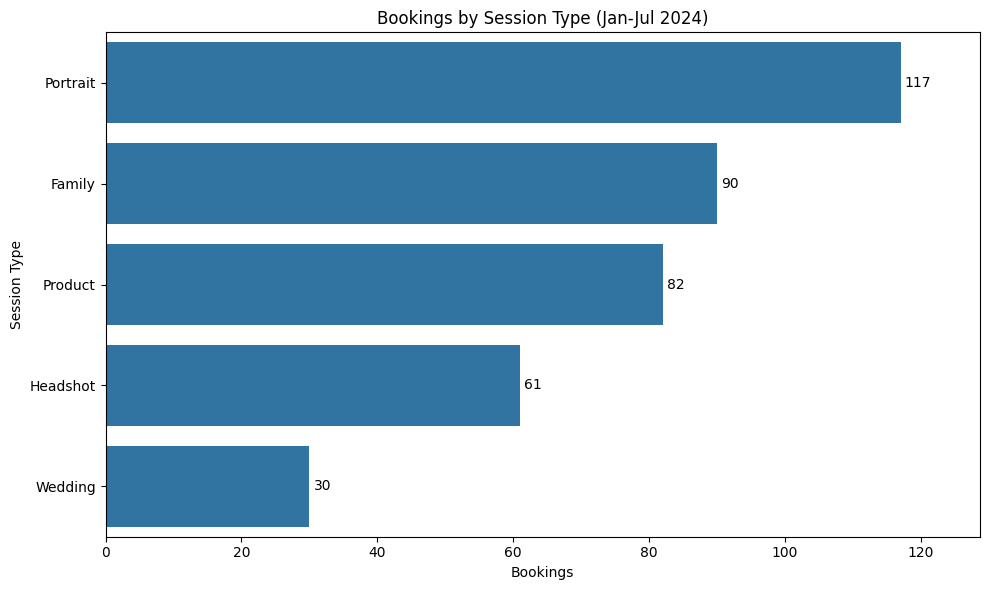

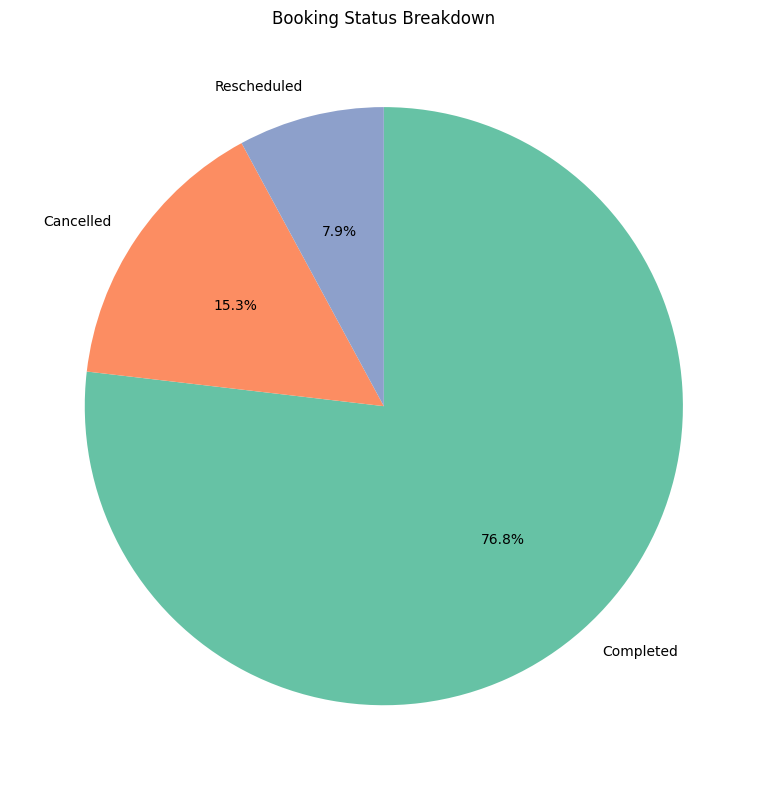

In [20]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Chart 1: booking count by session type (bar), same order as the Q1 table
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='book_count', y='session_type', data=book_count_by_session_type, ax=ax)
ax.set_title('Bookings by Session Type (Jan-Jul 2024)')
ax.set_xlabel('Bookings')
ax.set_ylabel('Session Type')
ax.bar_label(ax.containers[0], padding=3)
ax.margins(x=0.1)
plt.tight_layout()
plt.show()

# Chart 2: booking status breakdown (pie), same order as the Q2 table
fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(
    status_percentage['status_percentage'],
    labels=status_percentage['status'],
    colors=sns.color_palette('Set2'),
    autopct='%1.1f%%',
    startangle=90,
    counterclock=False,
)
ax.set_title('Booking Status Breakdown')
plt.tight_layout()
plt.show()


---
# 💼 Business Insights
*What did I discover?*

- Portrait is booked the most (**117**), but Wedding earns the most revenue (**$20,068**) from only **30** bookings.  
  (Portrait가 예약은 가장 많지만(**117**건), 매출은 **30**건뿐인 Wedding이 가장 높습니다(**$20,068**).)  
- **76.84%** of bookings are Completed, and **23.15%** are Cancelled or Rescheduled.  
  (예약의 **76.84%**가 완료이고, **23.15%**가 취소 또는 일정변경입니다.)  
- Headshot earns the least revenue at **$5,612**.  
  (Headshot의 매출이 **$5,612**로 가장 낮습니다.)  


---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Keep Wedding slots available, since **30** bookings earn **$20,068**.  
   (**30**건으로 **$20,068**을 버니 Wedding 일정을 확보해 둡니다.)  
2. Look into why **15.26%** of bookings are Cancelled.  
   (예약의 **15.26%**가 취소되는 이유를 살펴봅니다.)  
3. Review Headshot pricing or demand, since it has **61** bookings but only **$5,612** in revenue.  
   (Headshot은 예약이 **61**건인데 매출은 **$5,612**뿐이라 가격이나 수요를 살펴봅니다.)  


---
# ✅ What I Learned
*Today's biggest lesson*

- A percentage in DuckDB can use a subquery for the total, such as `COUNT(*) / (SELECT COUNT(*) FROM df)`.  
  (DuckDB에서 비율은 `COUNT(*) / (SELECT COUNT(*) FROM df)`처럼 서브쿼리로 전체를 구할 수 있습니다.)  
- The most booked session type is not the one with the most revenue.  
  (예약이 가장 많은 세션이 매출이 가장 높은 세션은 아닙니다.)  
-   


---
# 🧠 Reflection

**What was difficult?**  
Nothing in the three queries needed a change.  
(쿼리 세 개는 고칠 곳이 없었음)

**Why?**  
Each query uses one `GROUP BY` with `COUNT(*)` or `SUM(cost)`.  
(각 쿼리가 `COUNT(*)`나 `SUM(cost)`와 `GROUP BY` 하나를 씀)

**How did I solve it?**  
Used `ORDER BY ... DESC` so the top and lowest rows sit at the two ends.  
(`ORDER BY ... DESC`로 최고·최저 행이 양 끝에 오게 함)

**What would I do differently next time?**  
Compare the booking count order with the revenue order before writing an insight.  
(인사이트를 쓰기 전에 예약건수 순서와 매출 순서를 비교하기)


---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★★☆☆  
I can write grouped counts, percentages, and sums in DuckDB.  
(DuckDB에서 그룹별 건수, 비율, 합계를 쓸 수 있습니다.)  

**Confidence**  
★★★★★★★☆☆☆  

**Difficulty**  
★★★☆☆☆☆☆☆☆  


---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Day 61: Table merge  
  (Day 61: 테이블 병합)  
